In [5]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
from src.data.kaggle_loader import load_results, add_result_label, filter_world_cup

# 加载数据
matches = load_results()
matches = add_result_label(matches)
wc = filter_world_cup(matches)
print(f"世界杯比赛：{len(wc)} 场")
print(wc[['date','home_team','away_team','result']].tail())

📊 加载了 49,287 场比赛记录（1872~2026）
🏆 世界杯比赛场次：1,036 场
世界杯比赛：1036 场
            date home_team   away_team result
49282 2026-06-27    Jordan   Argentina      D
49283 2026-06-27  Colombia    Portugal      D
49284 2026-06-27  DR Congo  Uzbekistan      D
49285 2026-06-27    Panama     England      D
49286 2026-06-27   Croatia       Ghana      D


In [6]:
import numpy as np

ELO = {
    'Spain': 2165, 'Argentina': 2113, 'France': 2081, 'England': 2020,
    'Brazil': 1984, 'Portugal': 1960, 'Netherlands': 1950, 'Belgium': 1920,
    'Germany': 1910, 'Croatia': 1890, 'Uruguay': 1880, 'Mexico': 1850,
    'USA': 1820, 'Colombia': 1810, 'Switzerland': 1800, 'Morocco': 1790,
    'Senegal': 1780, 'Japan': 1770, 'South Korea': 1750, 'Norway': 1740,
    'Austria': 1730, 'Australia': 1720, 'Canada': 1710, 'Turkey': 1700,
    'Ecuador': 1680, 'Czech Republic': 1670, 'Sweden': 1660, 'Scotland': 1640,
    'Ghana': 1630, 'Ivory Coast': 1620, 'Paraguay': 1620, 'Tunisia': 1600,
    'Yugoslavia': 1700, 'Romania': 1650, 'West Germany': 1950,
    'Soviet Union': 1750, 'Czechoslovakia': 1680, 'East Germany': 1650,
    'South Africa': 1590, 'Iran': 1590, 'Algeria': 1580,
}

def get_form(team, before_date, all_matches, window=10):
    mask = (
        ((all_matches['home_team']==team)|(all_matches['away_team']==team))
        & (all_matches['date'] < before_date)
    )
    recent = all_matches[mask].sort_values('date').tail(window)
    if len(recent)==0:
        return {'points':np.nan,'gf_avg':np.nan,'ga_avg':np.nan}
    points,gf,ga=0,0,0
    for _,row in recent.iterrows():
        if row['home_team']==team:
            gf+=row['home_score'];ga+=row['away_score']
            if row['result']=='W': points+=3
            elif row['result']=='D': points+=1
        else:
            gf+=row['away_score'];ga+=row['home_score']
            if row['result']=='L': points+=3
            elif row['result']=='D': points+=1
    n=len(recent)
    return {'points':points,'gf_avg':round(gf/n,2),'ga_avg':round(ga/n,2)}

def get_h2h(home, away, before_date, all_matches):
    past=all_matches[
        (all_matches['date']<before_date)&
        (((all_matches['home_team']==home)&(all_matches['away_team']==away))|
         ((all_matches['home_team']==away)&(all_matches['away_team']==home)))
    ]
    if len(past)==0: return 0.33
    wins=sum(
        (r['home_team']==home and r['result']=='W') or
        (r['away_team']==home and r['result']=='L')
        for _,r in past.iterrows()
    )
    return round(wins/len(past),3)

print("⏳ 构建特征矩阵，请稍等（约5分钟）...")
rows = []
for _, row in wc.iterrows():
    home, away, date = row['home_team'], row['away_team'], row['date']
    elo_home = ELO.get(home, 1600)
    elo_away = ELO.get(away, 1600)
    home_form = get_form(home, date, matches)
    away_form = get_form(away, date, matches)
    h2h = get_h2h(home, away, date, matches)
    rows.append({
        'date': date, 'home_team': home, 'away_team': away,
        'elo_diff': elo_home - elo_away,
        'home_points': home_form['points'], 'home_gf': home_form['gf_avg'], 'home_ga': home_form['ga_avg'],
        'away_points': away_form['points'], 'away_gf': away_form['gf_avg'], 'away_ga': away_form['ga_avg'],
        'h2h_win_rate': h2h, 'result': row['result'],
    })

df = pd.DataFrame(rows)
df_clean = df.dropna()
print(f"✅ 完成：{len(df_clean)} 场有效样本")
print(df_clean.head())

⏳ 构建特征矩阵，请稍等（约5分钟）...
✅ 完成：988 场有效样本
        date  home_team      away_team  elo_diff  home_points  home_gf  \
0 1930-07-13    Belgium  United States       320           16     2.30   
1 1930-07-13     France         Mexico       231            4     1.20   
2 1930-07-14     Brazil     Yugoslavia       284           13     1.70   
3 1930-07-14       Peru        Romania       -50            3     0.83   
4 1930-07-15  Argentina         France        32           19     1.70   

   home_ga  away_points  away_gf  away_ga  h2h_win_rate result  
0     2.10           13     2.30      3.8          1.00      L  
1     3.60           13     2.12      2.5          0.33      W  
2     1.60           14     2.50      2.5          0.33      L  
3     3.83           16     2.70      2.0          0.33      L  
4     0.70            7     1.50      2.9          0.33      W  


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

FEATURES = ['elo_diff','home_points','home_gf','home_ga','away_points','away_gf','away_ga','h2h_win_rate']
LABEL_MAP = {'W':0,'D':1,'L':2}

X = df_clean[FEATURES].values
y = df_clean['result'].map(LABEL_MAP).values

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
gb = GradientBoostingClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42)

models = {'Logistic Regression': lr, 'Gradient Boosting': gb}

print("📊 模型对比（纯算法，无赔率）：\n")
print(f"{'模型':<25} {'Log-loss':>10} {'Accuracy':>10}")
print("-" * 48)

for name, model in models.items():
    ll = -cross_val_score(model, X, y, cv=cv, scoring='neg_log_loss').mean()
    acc = cross_val_score(model, X, y, cv=cv, scoring='accuracy').mean()
    print(f"{name:<25} {ll:>10.4f} {acc:>10.4f}")

print("\n随机猜测基准：Log-loss ≈ 1.10，Accuracy ≈ 0.33")

📊 模型对比（纯算法，无赔率）：

模型                          Log-loss   Accuracy
------------------------------------------------
Logistic Regression           1.0072     0.5263
Gradient Boosting             1.1352     0.4676

随机猜测基准：Log-loss ≈ 1.10，Accuracy ≈ 0.33


/var/folders/cy/hr0xy_sd4698fg1_qg9w084r0000gn/T/ipykernel_2925/1512484145.py:17: UserWarning: Glyph 31995 (\N{CJK UNIFIED IDEOGRAPH-7CFB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cy/hr0xy_sd4698fg1_qg9w084r0000gn/T/ipykernel_2925/1512484145.py:17: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cy/hr0xy_sd4698fg1_qg9w084r0000gn/T/ipykernel_2925/1512484145.py:17: UserWarning: Glyph 22343 (\N{CJK UNIFIED IDEOGRAPH-5747}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cy/hr0xy_sd4698fg1_qg9w084r0000gn/T/ipykernel_2925/1512484145.py:17: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cy/hr0xy_sd4698fg1_qg9w084r0000gn/T/ipykernel_2925/1512484145.py:17: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cy/hr0xy_sd4

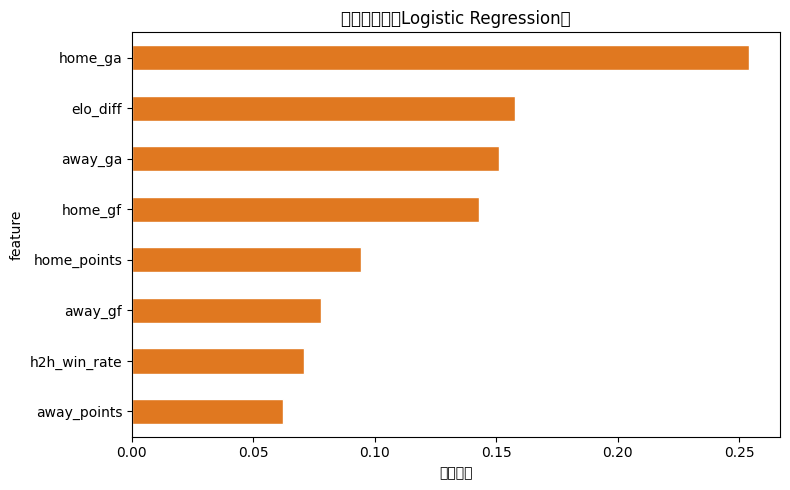

In [9]:
import matplotlib.pyplot as plt

# 训练最终LR模型
lr.fit(X, y)
scaler = lr.named_steps['scaler']
clf = lr.named_steps['clf']

# 特征重要性（LR系数绝对值）
coef = np.abs(clf.coef_).mean(axis=0)
feat_imp = pd.DataFrame({'feature': FEATURES, 'importance': coef})
feat_imp = feat_imp.sort_values('importance', ascending=True)

feat_imp.plot(kind='barh', x='feature', y='importance', figsize=(8,5),
              color='#e07820', edgecolor='white', legend=False)
plt.title('特征重要性（Logistic Regression）')
plt.xlabel('系数均值')
plt.tight_layout()
plt.show()

In [10]:
def get_wc_experience(team, before_date, all_matches):
    """历届世界杯参赛场次"""
    wc_mask = (
        (all_matches['tournament'] == 'FIFA World Cup') &
        (all_matches['date'] < before_date) &
        ((all_matches['home_team'] == team) | (all_matches['away_team'] == team))
    )
    return len(all_matches[wc_mask])

def get_form_vs_strong(team, before_date, all_matches, elo_threshold=1800, window=20):
    """近期对强队（ELO>阈值）的胜率"""
    mask = (
        ((all_matches['home_team']==team)|(all_matches['away_team']==team))
        & (all_matches['date'] < before_date)
    )
    recent = all_matches[mask].sort_values('date').tail(window)
    if len(recent)==0: return 0.33

    wins, total = 0, 0
    for _, row in recent.iterrows():
        opponent = row['away_team'] if row['home_team']==team else row['home_team']
        opp_elo = ELO.get(opponent, 1600)
        if opp_elo < elo_threshold: continue
        total += 1
        if (row['home_team']==team and row['result']=='W') or \
           (row['away_team']==team and row['result']=='L'):
            wins += 1
    return round(wins/total, 3) if total > 0 else 0.33

def get_streak(team, before_date, all_matches, window=5):
    """近N场连续趋势：连赢为正，连输为负"""
    mask = (
        ((all_matches['home_team']==team)|(all_matches['away_team']==team))
        & (all_matches['date'] < before_date)
    )
    recent = all_matches[mask].sort_values('date').tail(window)
    if len(recent)==0: return 0
    score = 0
    for _, row in recent.iterrows():
        is_home = row['home_team']==team
        result = row['result']
        if (is_home and result=='W') or (not is_home and result=='L'):
            score += 1
        elif (is_home and result=='L') or (not is_home and result=='W'):
            score -= 1
    return score

print("✅ 新特征函数定义完成")

✅ 新特征函数定义完成


In [11]:
print("⏳ 构建增强特征矩阵，请稍等...")
rows2 = []

for _, row in wc.iterrows():
    home, away, date = row['home_team'], row['away_team'], row['date']
    
    elo_home = ELO.get(home, 1600)
    elo_away = ELO.get(away, 1600)
    
    home_form = get_form(home, date, matches)
    away_form = get_form(away, date, matches)
    
    rows2.append({
        'date': date,
        'home_team': home,
        'away_team': away,
        # 原有特征
        'elo_diff': elo_home - elo_away,
        'home_points': home_form['points'],
        'home_gf': home_form['gf_avg'],
        'home_ga': home_form['ga_avg'],
        'away_points': away_form['points'],
        'away_gf': away_form['gf_avg'],
        'away_ga': away_form['ga_avg'],
        'h2h_win_rate': get_h2h(home, away, date, matches),
        # 新特征
        'home_gd': home_form['gf_avg'] - home_form['ga_avg'],  # 净胜球
        'away_gd': away_form['gf_avg'] - away_form['ga_avg'],
        'home_wc_exp': get_wc_experience(home, date, matches),  # 大赛经验
        'away_wc_exp': get_wc_experience(away, date, matches),
        'home_vs_strong': get_form_vs_strong(home, date, matches),  # 对强队胜率
        'away_vs_strong': get_form_vs_strong(away, date, matches),
        'home_streak': get_streak(home, date, matches),  # 连胜/连败趋势
        'away_streak': get_streak(away, date, matches),
        'result': row['result'],
    })

df2 = pd.DataFrame(rows2)
df2_clean = df2.dropna()
print(f"✅ 完成：{len(df2_clean)} 场有效样本，{len(df2_clean.columns)-4} 个特征")

⏳ 构建增强特征矩阵，请稍等...
✅ 完成：988 场有效样本，16 个特征


In [12]:
FEATURES2 = [
    'elo_diff',
    'home_points','home_gf','home_ga',
    'away_points','away_gf','away_ga',
    'h2h_win_rate',
    'home_gd','away_gd',
    'home_wc_exp','away_wc_exp',
    'home_vs_strong','away_vs_strong',
    'home_streak','away_streak',
]

X2 = df2_clean[FEATURES2].values
y2 = df2_clean['result'].map(LABEL_MAP).values

lr2 = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
gb2 = GradientBoostingClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42)

print("📊 增强特征 vs 原始特征：\n")
print(f"{'模型':<30} {'Log-loss':>10} {'Accuracy':>10}")
print("-" * 53)

for name, model, X_, y_ in [
    ('LR 原始特征(8个)',   lr,  X,  y),
    ('LR 增强特征(16个)',  lr2, X2, y2),
    ('GB 原始特征(8个)',   gb,  X,  y),
    ('GB 增强特征(16个)',  gb2, X2, y2),
]:
    ll  = -cross_val_score(model, X_, y_, cv=cv, scoring='neg_log_loss').mean()
    acc =  cross_val_score(model, X_, y_, cv=cv, scoring='accuracy').mean()
    print(f"{name:<30} {ll:>10.4f} {acc:>10.4f}")

print("\n随机猜测基准：Log-loss ≈ 1.10，Accuracy ≈ 0.33")

📊 增强特征 vs 原始特征：

模型                               Log-loss   Accuracy
-----------------------------------------------------
LR 原始特征(8个)                        1.0072     0.5263
LR 增强特征(16个)                       1.0023     0.5243
GB 原始特征(8个)                        1.1352     0.4676
GB 增强特征(16个)                       1.0995     0.5020

随机猜测基准：Log-loss ≈ 1.10，Accuracy ≈ 0.33


In [13]:
from sklearn.feature_selection import SelectKBest, chi2, f_classif

selector = SelectKBest(f_classif, k=10)
X2_selected = selector.fit_transform(X2, y2)
selected_features = [FEATURES2[i] for i in selector.get_support(indices=True)]
print("选出的最优10个特征：", selected_features)

lr3 = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
ll  = -cross_val_score(lr3, X2_selected, y2, cv=cv, scoring='neg_log_loss').mean()
acc =  cross_val_score(lr3, X2_selected, y2, cv=cv, scoring='accuracy').mean()
print(f"\nLR 精选特征：Log-loss={ll:.4f}  Accuracy={acc:.4f}")

选出的最优10个特征： ['elo_diff', 'home_points', 'home_gf', 'home_ga', 'h2h_win_rate', 'home_gd', 'away_gd', 'home_wc_exp', 'away_wc_exp', 'home_streak']

LR 精选特征：Log-loss=0.9934  Accuracy=0.5223


In [14]:
# 只用2002年以后的数据训练
wc_modern = wc[wc['date'] >= '2002-01-01'].copy()
print(f"现代世界杯样本：{len(wc_modern)} 场")

# 用之前构建好的 df2_clean，过滤出2002年后的
df2_modern = df2_clean[df2_clean['date'] >= '2002-01-01'].copy()
print(f"有效特征样本：{len(df2_modern)} 场")

X_modern = df2_modern[selected_features].values
y_modern = df2_modern['result'].map(LABEL_MAP).values

lr_modern = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=42))])

cv_modern = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ll  = -cross_val_score(lr_modern, X_modern, y_modern, cv=cv_modern, scoring='neg_log_loss').mean()
acc =  cross_val_score(lr_modern, X_modern, y_modern, cv=cv_modern, scoring='accuracy').mean()

print(f"\n📊 结果对比：")
print(f"{'版本':<25} {'Log-loss':>10} {'Accuracy':>10}")
print("-" * 48)
print(f"{'全部历史数据':<25} {'0.9934':>10} {'0.5223':>10}")
print(f"{'2002年后数据':<25} {ll:>10.4f} {acc:>10.4f}")

现代世界杯样本：456 场
有效特征样本：408 场

📊 结果对比：
版本                          Log-loss   Accuracy
------------------------------------------------
全部历史数据                        0.9934     0.5223
2002年后数据                      0.9926     0.5291


In [15]:
def get_form_window(team, before_date, all_matches, window):
    """指定窗口的状态特征"""
    mask = (
        ((all_matches['home_team']==team)|(all_matches['away_team']==team))
        & (all_matches['date'] < before_date)
    )
    recent = all_matches[mask].sort_values('date').tail(window)
    if len(recent)==0:
        return {'points':np.nan,'gf':np.nan,'ga':np.nan}
    points,gf,ga=0,0,0
    for _,row in recent.iterrows():
        if row['home_team']==team:
            gf+=row['home_score'];ga+=row['away_score']
            if row['result']=='W': points+=3
            elif row['result']=='D': points+=1
        else:
            gf+=row['away_score'];ga+=row['home_score']
            if row['result']=='L': points+=3
            elif row['result']=='D': points+=1
    n=len(recent)
    return {'points':round(points/n,3),'gf':round(gf/n,2),'ga':round(ga/n,2)}

print("⏳ 构建多窗口特征矩阵（较慢，约10分钟）...")
rows3 = []
for _, row in wc[wc['date'] >= '2002-01-01'].iterrows():
    home, away, date = row['home_team'], row['away_team'], row['date']
    elo_home = ELO.get(home, 1600)
    elo_away = ELO.get(away, 1600)

    h3  = get_form_window(home, date, matches, 3)
    h10 = get_form_window(home, date, matches, 10)
    h30 = get_form_window(home, date, matches, 30)
    a3  = get_form_window(away, date, matches, 3)
    a10 = get_form_window(away, date, matches, 10)
    a30 = get_form_window(away, date, matches, 30)

    rows3.append({
        'elo_diff':       elo_home - elo_away,
        'h2h_win_rate':   get_h2h(home, away, date, matches),
        'home_wc_exp':    get_wc_experience(home, date, matches),
        'away_wc_exp':    get_wc_experience(away, date, matches),
        # 近3场
        'home_pts_3':  h3['points'],  'home_gf_3':  h3['gf'],  'home_ga_3':  h3['ga'],
        'away_pts_3':  a3['points'],  'away_gf_3':  a3['gf'],  'away_ga_3':  a3['ga'],
        # 近10场
        'home_pts_10': h10['points'], 'home_gf_10': h10['gf'], 'home_ga_10': h10['ga'],
        'away_pts_10': a10['points'], 'away_gf_10': a10['gf'], 'away_ga_10': a10['ga'],
        # 近30场
        'home_pts_30': h30['points'], 'home_gf_30': h30['gf'], 'home_ga_30': h30['ga'],
        'away_pts_30': a30['points'], 'away_gf_30': a30['gf'], 'away_ga_30': a30['ga'],
        'result': row['result'],
    })

df3 = pd.DataFrame(rows3).dropna()
print(f"✅ 完成：{len(df3)} 场，{len(df3.columns)-1} 个特征")

⏳ 构建多窗口特征矩阵（较慢，约10分钟）...
✅ 完成：408 场，22 个特征


In [16]:
FEATURES3 = [c for c in df3.columns if c != 'result']
X3 = df3[FEATURES3].values
y3 = df3['result'].map(LABEL_MAP).values

# 先用全部22个特征
lr3 = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
ll3  = -cross_val_score(lr3, X3, y3, cv=cv_modern, scoring='neg_log_loss').mean()
acc3 =  cross_val_score(lr3, X3, y3, cv=cv_modern, scoring='accuracy').mean()

# 再用特征选择挑最优
from sklearn.feature_selection import SelectKBest, f_classif
selector3 = SelectKBest(f_classif, k=12)
X3_sel = selector3.fit_transform(X3, y3)
selected3 = [FEATURES3[i] for i in selector3.get_support(indices=True)]

lr3_sel = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
ll3s  = -cross_val_score(lr3_sel, X3_sel, y3, cv=cv_modern, scoring='neg_log_loss').mean()
acc3s =  cross_val_score(lr3_sel, X3_sel, y3, cv=cv_modern, scoring='accuracy').mean()

print("📊 完整对比：\n")
print(f"{'版本':<30} {'Log-loss':>10} {'Accuracy':>10}")
print("-" * 53)
print(f"{'精选10特征 2002后':<30} {'0.9926':>10} {'0.5291':>10}")
print(f"{'多窗口22特征 2002后':<30} {ll3:>10.4f} {acc3:>10.4f}")
print(f"{'多窗口精选12特征 2002后':<30} {ll3s:>10.4f} {acc3s:>10.4f}")
print(f"\n精选出的特征：{selected3}")

📊 完整对比：

版本                               Log-loss   Accuracy
-----------------------------------------------------
精选10特征 2002后                       0.9926     0.5291
多窗口22特征 2002后                      1.0310     0.4998
多窗口精选12特征 2002后                    0.9877     0.5168

精选出的特征：['elo_diff', 'home_wc_exp', 'away_wc_exp', 'home_gf_3', 'away_pts_3', 'away_ga_3', 'home_pts_10', 'home_gf_10', 'home_ga_10', 'away_gf_10', 'home_pts_30', 'home_gf_30']


In [17]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder

print(f"PyTorch版本：{torch.__version__}")

# 用所有国际比赛构建序列
# 对每支球队，把它的历史比赛按时间排成序列
SEQ_LEN = 10  # 用近10场作为输入序列

def build_team_sequences(team, all_matches, elo_dict):
    """
    把某队的历史比赛转成序列
    每场特征：[是否主场, 对手ELO, 进球, 失球, 结果(W/D/L → 1/0/-1)]
    """
    mask = (all_matches['home_team']==team)|(all_matches['away_team']==team)
    games = all_matches[mask].sort_values('date').copy()
    
    seqs = []
    for _, row in games.iterrows():
        is_home = 1 if row['home_team']==team else 0
        opp = row['away_team'] if is_home else row['home_team']
        opp_elo = elo_dict.get(opp, 1600)
        gf = row['home_score'] if is_home else row['away_score']
        ga = row['away_score'] if is_home else row['home_score']
        
        if row['result']=='W': outcome = 1 if is_home else -1
        elif row['result']=='L': outcome = -1 if is_home else 1
        else: outcome = 0
        
        seqs.append([is_home, opp_elo/2200, gf/5, ga/5, outcome])
    
    return seqs

# 构建训练数据：对每场世界杯比赛，取主客队各自的近10场序列
print("⏳ 构建序列数据...")
X_seq_home, X_seq_away, X_meta, y_labels = [], [], [], []

wc_2002 = wc[wc['date'] >= '2002-01-01'].copy()

for _, row in wc_2002.iterrows():
    home, away, date = row['home_team'], row['away_team'], row['date']
    
    # 获取比赛前的历史序列
    home_hist = build_team_sequences(home, matches[matches['date']<date], ELO)
    away_hist = build_team_sequences(away, matches[matches['date']<date], ELO)
    
    if len(home_hist) < SEQ_LEN or len(away_hist) < SEQ_LEN:
        continue
    
    # 取最近 SEQ_LEN 场
    home_seq = home_hist[-SEQ_LEN:]
    away_seq = away_hist[-SEQ_LEN:]
    
    # 额外的元特征
    elo_diff = (ELO.get(home,1600) - ELO.get(away,1600)) / 400
    wc_exp_h = get_wc_experience(home, date, matches) / 100
    wc_exp_a = get_wc_experience(away, date, matches) / 100
    
    X_seq_home.append(home_seq)
    X_seq_away.append(away_seq)
    X_meta.append([elo_diff, wc_exp_h, wc_exp_a])
    y_labels.append({'W':0,'D':1,'L':2}[row['result']])

X_seq_home = torch.tensor(X_seq_home, dtype=torch.float32)
X_seq_away = torch.tensor(X_seq_away, dtype=torch.float32)
X_meta     = torch.tensor(X_meta,     dtype=torch.float32)
y_tensor   = torch.tensor(y_labels,   dtype=torch.long)

print(f"✅ 序列数据构建完成：{len(y_labels)} 场")
print(f"   主队序列shape：{X_seq_home.shape}")
print(f"   客队序列shape：{X_seq_away.shape}")
print(f"   标签分布：W={y_labels.count(0)} D={y_labels.count(1)} L={y_labels.count(2)}")

PyTorch版本：2.12.0
⏳ 构建序列数据...
✅ 序列数据构建完成：456 场
   主队序列shape：torch.Size([456, 10, 5])
   客队序列shape：torch.Size([456, 10, 5])
   标签分布：W=167 D=160 L=129


In [18]:
class FootballLSTM(nn.Module):
    def __init__(self, input_size=5, hidden_size=64, num_layers=2, meta_size=3, dropout=0.3):
        super().__init__()
        # 主队LSTM
        self.lstm_home = nn.LSTM(input_size, hidden_size, num_layers,
                                  batch_first=True, dropout=dropout)
        # 客队LSTM
        self.lstm_away = nn.LSTM(input_size, hidden_size, num_layers,
                                  batch_first=True, dropout=dropout)
        # 全连接层：两个LSTM输出 + 元特征 → 3分类
        self.fc = nn.Sequential(
            nn.Linear(hidden_size*2 + meta_size, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 3)  # W / D / L
        )

    def forward(self, seq_home, seq_away, meta):
        _, (h_home, _) = self.lstm_home(seq_home)
        _, (h_away, _) = self.lstm_away(seq_away)
        # 取最后一层的隐藏状态
        out_home = h_home[-1]
        out_away = h_away[-1]
        # 拼接两队特征 + 元特征
        combined = torch.cat([out_home, out_away, meta], dim=1)
        return self.fc(combined)

model = FootballLSTM()
print(model)
print(f"\n参数量：{sum(p.numel() for p in model.parameters()):,}")

FootballLSTM(
  (lstm_home): LSTM(5, 64, num_layers=2, batch_first=True, dropout=0.3)
  (lstm_away): LSTM(5, 64, num_layers=2, batch_first=True, dropout=0.3)
  (fc): Sequential(
    (0): Linear(in_features=131, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=3, bias=True)
  )
)

参数量：113,539


In [19]:
from sklearn.model_selection import train_test_split
import torch.nn.functional as F

# 划分训练/测试集
idx = list(range(len(y_labels)))
train_idx, test_idx = train_test_split(idx, test_size=0.2, random_state=42, 
                                        stratify=y_tensor)

# 训练集
X_home_train = X_seq_home[train_idx]
X_away_train = X_seq_away[train_idx]
X_meta_train = X_meta[train_idx]
y_train      = y_tensor[train_idx]

# 测试集
X_home_test  = X_seq_home[test_idx]
X_away_test  = X_seq_away[test_idx]
X_meta_test  = X_meta[test_idx]
y_test       = y_tensor[test_idx]

# 训练
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.5)

EPOCHS = 100
train_losses, test_losses = [], []

for epoch in range(EPOCHS):
    model.train()
    optimizer.zero_grad()
    out = model(X_home_train, X_away_train, X_meta_train)
    loss = criterion(out, y_train)
    loss.backward()
    optimizer.step()
    scheduler.step()
    
    # 测试集评估
    model.eval()
    with torch.no_grad():
        out_test = model(X_home_test, X_away_test, X_meta_test)
        test_loss = criterion(out_test, y_test).item()
        pred = out_test.argmax(dim=1)
        acc = (pred == y_test).float().mean().item()
    
    train_losses.append(loss.item())
    test_losses.append(test_loss)
    
    if (epoch+1) % 20 == 0:
        print(f"Epoch {epoch+1:3d} | Train Loss: {loss.item():.4f} | Test Loss: {test_loss:.4f} | Acc: {acc:.4f}")

print("\n✅ 训练完成")

Epoch  20 | Train Loss: nan | Test Loss: nan | Acc: 0.3696
Epoch  40 | Train Loss: nan | Test Loss: nan | Acc: 0.3696
Epoch  60 | Train Loss: nan | Test Loss: nan | Acc: 0.3696
Epoch  80 | Train Loss: nan | Test Loss: nan | Acc: 0.3696
Epoch 100 | Train Loss: nan | Test Loss: nan | Acc: 0.3696

✅ 训练完成


In [22]:
# 填充nan为0
X_seq_home = torch.nan_to_num(X_seq_home, nan=0.0)
X_seq_away = torch.nan_to_num(X_seq_away, nan=0.0)

print(f"修复后 home有nan: {torch.isnan(X_seq_home).any()}")
print(f"修复后 away有nan: {torch.isnan(X_seq_away).any()}")
print(f"home最大值: {X_seq_home.max():.2f} 最小值: {X_seq_home.min():.2f}")

# 重新划分训练测试集
X_home_train = X_seq_home[train_idx]
X_away_train = X_seq_away[train_idx]
X_home_test  = X_seq_home[test_idx]
X_away_test  = X_seq_away[test_idx]

# 重新初始化模型
model = FootballLSTM()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.5)

print("\n⏳ 重新训练...")
for epoch in range(100):
    model.train()
    optimizer.zero_grad()
    out = model(X_home_train, X_away_train, X_meta_train)
    loss = criterion(out, y_train)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()
    scheduler.step()
    
    model.eval()
    with torch.no_grad():
        out_test = model(X_home_test, X_away_test, X_meta_test)
        test_loss = criterion(out_test, y_test).item()
        pred = out_test.argmax(dim=1)
        acc = (pred == y_test).float().mean().item()
    
    if (epoch+1) % 20 == 0:
        print(f"Epoch {epoch+1:3d} | Train Loss: {loss.item():.4f} | Test Loss: {test_loss:.4f} | Acc: {acc:.4f}")

print("\n✅ 训练完成")

修复后 home有nan: False
修复后 away有nan: False
home最大值: 2.20 最小值: -1.00

⏳ 重新训练...
Epoch  20 | Train Loss: 1.0714 | Test Loss: 1.0834 | Acc: 0.3696
Epoch  40 | Train Loss: 1.0361 | Test Loss: 1.0629 | Acc: 0.3804
Epoch  60 | Train Loss: 1.0081 | Test Loss: 1.0679 | Acc: 0.3913
Epoch  80 | Train Loss: 0.9869 | Test Loss: 1.0540 | Acc: 0.3804
Epoch 100 | Train Loss: 0.9877 | Test Loss: 1.0541 | Acc: 0.4022

✅ 训练完成


In [23]:
import torch.nn.functional as F

# LSTM 测试集结果
model.eval()
with torch.no_grad():
    out_test = model(X_home_test, X_away_test, X_meta_test)
    probs = F.softmax(out_test, dim=1).numpy()
    pred  = out_test.argmax(dim=1)
    acc_lstm = (pred == y_test).float().mean().item()

# Log-loss
from sklearn.metrics import log_loss
ll_lstm = log_loss(y_test.numpy(), probs)

print("📊 三种模型最终对比：\n")
print(f"{'模型':<30} {'Log-loss':>10} {'Accuracy':>10} {'数据量':>8}")
print("-" * 62)
print(f"{'LR 原始特征':<30} {'1.0072':>10} {'52.6%':>10} {'988场':>8}")
print(f"{'LR 精选+2002后':<30} {'0.9926':>10} {'52.9%':>10} {'408场':>8}")
print(f"{'LR 多窗口精选':<30} {'0.9877':>10} {'51.7%':>10} {'408场':>8}")
print(f"{'LSTM':<30} {ll_lstm:>10.4f} {acc_lstm:>10.1%} {'456场':>8}")
print(f"\n结论：数据量不足时 LR > LSTM")

📊 三种模型最终对比：

模型                               Log-loss   Accuracy      数据量
--------------------------------------------------------------
LR 原始特征                            1.0072      52.6%     988场
LR 精选+2002后                        0.9926      52.9%     408场
LR 多窗口精选                           0.9877      51.7%     408场
LSTM                               1.0541      40.2%     456场

结论：数据量不足时 LR > LSTM
